In [18]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [53]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [100]:
# Project directories
BASE_DIR = "/content/drive/MyDrive/AQI Prediction Project"

MODEL_DIR = os.path.join(BASE_DIR, "Model Files")
RESULT_DIR = os.path.join(BASE_DIR, "Results and Graphs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Model folder:", MODEL_DIR)
print("Results folder:", RESULT_DIR)

Model folder: /content/drive/MyDrive/AQI Prediction Project/Model Files
Results folder: /content/drive/MyDrive/AQI Prediction Project/Results and Graphs


In [54]:
DATA_PATH = ( "/content/city_day_cleaned.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [32]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types:
City           object
Date           object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket     object
dtype: object

Missing values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data co

In [63]:
#Select the target and input features

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# AQI is the value our models must predict
TARGET = "AQI"

if TARGET not in df.columns:
    raise ValueError(
        "AQI column not found. Check the dataset columns above."
    )

# Select numeric columns
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

# Exclude the target from input features
feature_columns = [
    col for col in numeric_columns
    if col != TARGET
]

# Exclude AQI-related derived columns if they exist
feature_columns = [
    col for col in feature_columns
    if col.lower() not in ["aqi_bucket", "aqi_category"]
]

# Keep only rows with a valid target
df_model = df.dropna(subset=[TARGET]).copy()

# Remove rows with infinite target values
df_model = df_model[
    np.isfinite(df_model[TARGET])
].copy()

X = df_model[feature_columns].copy()
y = df_model[TARGET].copy()

print("Input features:", feature_columns)
print("\nNumber of input features:", len(feature_columns))
print("Target:", TARGET)
print("X shape:", X.shape)
print("y shape:", y.shape)

Input features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']

Number of input features: 12
Target: AQI
X shape: (24850, 12)
y shape: (24850,)


In [64]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

Training samples: 19880
Testing samples: 4970
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [65]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=2,
            random_state=RANDOM_STATE
        ))
    ])
}

print("All four model pipelines created.")

All four model pipelines created.


In [66]:
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("Training completed for all four models.")

Training Linear Regression...
Linear Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Gradient Boosting...
Gradient Boosting trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training completed for all four models.


In [78]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


results = []

for name, model in trained_models.items():
    metrics = evaluate_model(model, X_test, y_test)

    results.append({
        "Model": name,
        **metrics
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2
0,Random Forest,20.7611,1651.2506,40.6356,0.9098
1,Gradient Boosting,23.6586,1879.6032,43.3544,0.8974
2,Decision Tree,24.7162,2589.9272,50.8913,0.8586
3,Linear Regression,31.1698,3533.0732,59.4397,0.8071


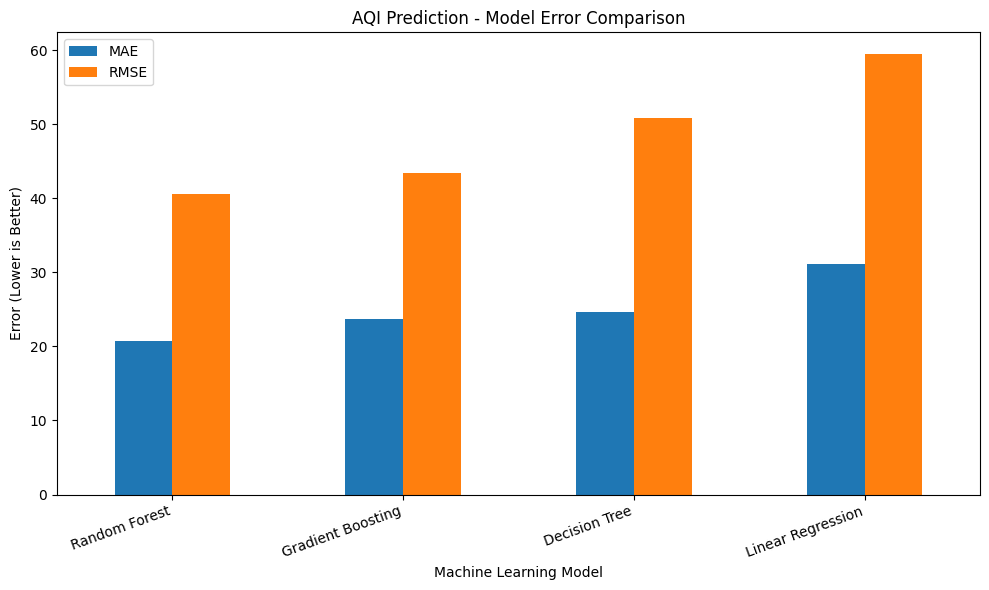

Graph saved at: /content/drive/MyDrive/AQI Prediction Project/Results and Graphs/model_error_comparison.png


In [92]:
#Graph 1: MAE and RMSE comparison
plt.figure(figsize=(10, 6))

results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    ax=plt.gca()
)

plt.title("AQI Prediction - Model Error Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Error (Lower is Better)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

graph_path = os.path.join(
    RESULT_DIR, "model_error_comparison.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", graph_path)

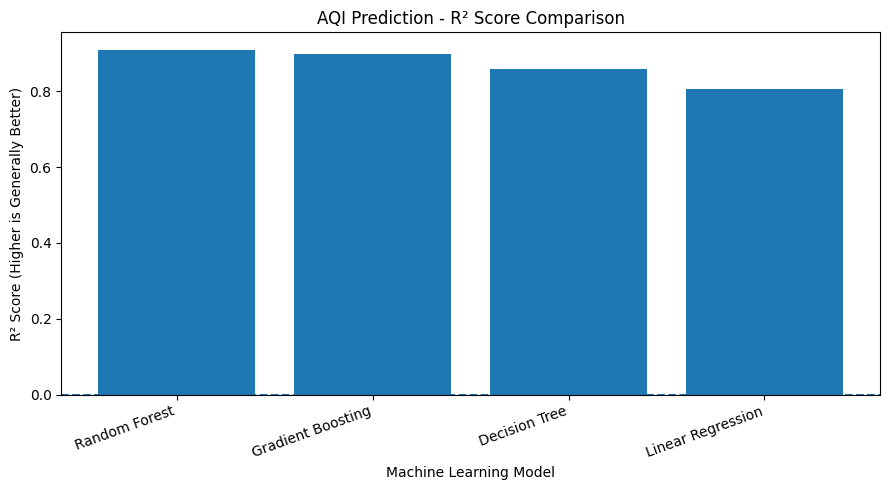

Graph saved at: /content/drive/MyDrive/AQI Prediction Project/Results and Graphs/r2_score_comparison.png


In [93]:
#Graph 2: R² comparison
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["R2"])

plt.title("AQI Prediction - R² Score Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score (Higher is Generally Better)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

graph_path = os.path.join(
    RESULT_DIR, "r2_score_comparison.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", graph_path)

In [81]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("\nBest model performance:")

display(
    results_df.iloc[[0]].round(4)
)

Best model: Random Forest

Best model performance:


,Model,MAE,MSE,RMSE,R2
0,Random Forest,20.7611,1651.2506,40.6356,0.9098


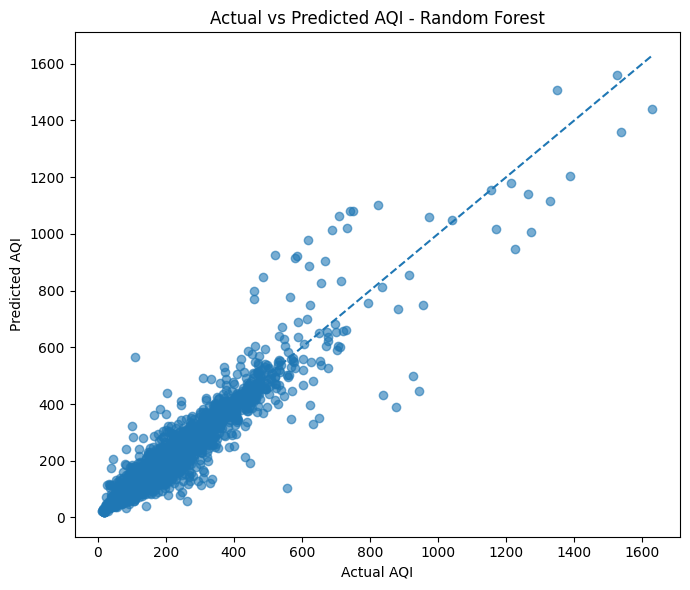

Graph saved at: /content/drive/MyDrive/AQI Prediction Project/Results and Graphs/actual_vs_predicted_aqi.png


In [94]:
#Graph 3: Actual AQI vs predicted AQI
import numpy as np

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 6))

plt.scatter(y_test, best_predictions, alpha=0.6)

min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.title(f"Actual vs Predicted AQI - {best_model_name}")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.tight_layout()

graph_path = os.path.join(
    RESULT_DIR, "actual_vs_predicted_aqi.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", graph_path)

,Feature,Importance
0,PM2.5,0.489662
6,CO,0.368986
1,PM10,0.037570
2,NO,0.037329
8,O3,0.013983
4,NOx,0.011938
7,SO2,0.009985
3,NO2,0.008210
10,Toluene,0.007552
11,Xylene,0.006080


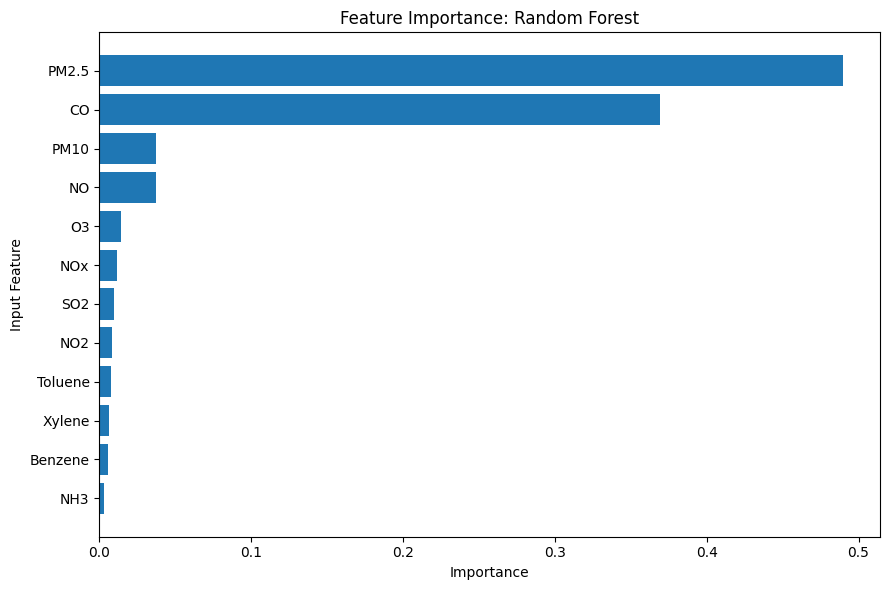

In [101]:
# Graph 4: Feature importance / coefficients

best_estimator = best_model.named_steps["model"]

if hasattr(best_estimator, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": best_estimator.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df)

    plt.figure(figsize=(9, 6))

    plt.barh(
        importance_df["Feature"][::-1],
        importance_df["Importance"][::-1]
    )

    plt.title(f"Feature Importance: {best_model_name}")
    plt.xlabel("Importance")
    plt.ylabel("Input Feature")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULT_DIR, "feature_importance.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

elif hasattr(best_estimator, "coef_"):

    coefficient_df = pd.DataFrame({
        "Feature": X_train.columns,
        "Coefficient": best_estimator.coef_
    })

    coefficient_df["Absolute Coefficient"] = (
        coefficient_df["Coefficient"].abs()
    )

    coefficient_df = coefficient_df.sort_values(
        "Absolute Coefficient",
        ascending=False
    )

    display(coefficient_df)

    plt.figure(figsize=(9, 6))

    plt.barh(
        coefficient_df["Feature"][::-1],
        coefficient_df["Coefficient"][::-1]
    )

    plt.title(f"Regression Coefficients: {best_model_name}")
    plt.xlabel("Coefficient")
    plt.ylabel("Input Feature")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULT_DIR, "feature_importance.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("Feature importance is not available for this model.")

In [95]:
prediction_results = pd.DataFrame({
    "Actual_AQI": np.asarray(y_test),
    "Predicted_AQI": best_predictions
})

prediction_results.to_csv(
    os.path.join(RESULT_DIR, "best_model_predictions.csv"),
    index=False
)

print("Prediction results saved!")

Prediction results saved!


In [97]:
# Create output folders in Google Drive
MODEL_DIR = (
    "/content/drive/MyDrive/AQI Prediction Project/Model Files"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Save the best model and metadata together
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": feature_columns,
    "target_column": TARGET,
    "metrics": results_df.iloc[0].to_dict()
}

model_path = os.path.join(
    MODEL_DIR,
    "best_model.joblib"
)

joblib.dump(model_artifact, model_path)

print("Best model saved at:")
print(model_path)

Best model saved at:
/content/drive/MyDrive/AQI Prediction Project/Model Files/best_model.joblib
